In [8]:

# Checking the Python version

import sys

print("Python Version:")
print(sys.version)

# Checking whether our notebook is running

print("\nEnvironment is working successfully!")


Python Version:
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Environment is working successfully!



# Machine Learning Assignment 2
## Multiclass Classification of Dry Beans

**Programme:** M.Tech Artificial Intelligence and Machine Learning

**Dataset:** Dry Bean Dataset

**Classification Type:** Multiclass Classification

**Algorithms Used:**
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

**Evaluation Metrics:**
1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)


In [9]:

# Step 1: Importing the required libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import os
import zipfile
import joblib

# Importing functions for splitting the dataset
from sklearn.model_selection import train_test_split

# Importing preprocessing tools
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Importing the five classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Importing evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All required libraries have been imported successfully!")


All required libraries have been imported successfully!


In [10]:

# Step 2: Uploading the Dry Bean dataset

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")


Saving dry+bean+dataset.zip to dry+bean+dataset.zip
Dataset uploaded successfully!


In [11]:

# Step 3: Extracting the dataset ZIP file

# Get the uploaded ZIP filename
zip_filename = list(uploaded.keys())[0]

# Extract all files from the ZIP folder
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall("DryBeanData")

print("Dataset extracted successfully!")

# Display the extracted files
for root, folders, filenames in os.walk("DryBeanData"):
    for filename in filenames:
        print(os.path.join(root, filename))


Dataset extracted successfully!
DryBeanData/DryBeanDataset/Dry_Bean_Dataset.xlsx
DryBeanData/DryBeanDataset/Dry_Bean_Dataset.txt
DryBeanData/DryBeanDataset/Dry_Bean_Dataset.arff


In [12]:

# Step 4: Loading the Dry Bean dataset

dataset_path = "DryBeanData/DryBeanDataset/Dry_Bean_Dataset.xlsx"

# Read the Excel file
df = pd.read_excel(dataset_path)

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())


First five rows of the dataset:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [13]:

# Step 5: Checking the size of the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset information:")
df.info()


Number of rows: 13611
Number of columns: 17

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float

In [14]:

# Step 6: Displaying all column names

print("Columns present in the dataset:\n")

for column in df.columns:
    print(column)


Columns present in the dataset:

Area
Perimeter
MajorAxisLength
MinorAxisLength
AspectRation
Eccentricity
ConvexArea
EquivDiameter
Extent
Solidity
roundness
Compactness
ShapeFactor1
ShapeFactor2
ShapeFactor3
ShapeFactor4
Class


In [15]:

# Step 7: Checking for missing values

print("Missing values in each column:\n")

print(df.isnull().sum())

print("\nTotal missing values:",
      df.isnull().sum().sum())


Missing values in each column:

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Total missing values: 0


In [16]:

# Step 8: Counting the number of records in each class

print("Number of records in each bean category:\n")

print(df['Class'].value_counts())


Number of records in each bean category:

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


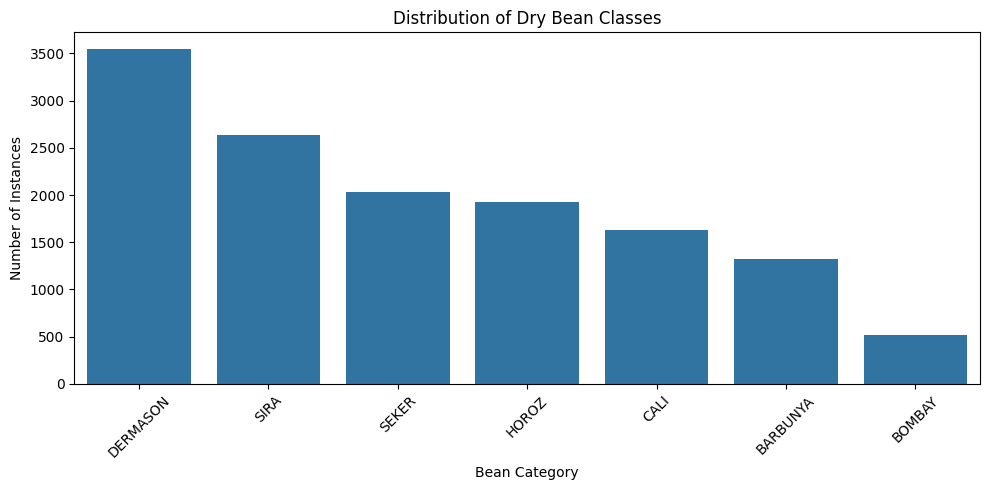

In [17]:

# Visualizing the distribution of bean varieties

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Class',
    order=df['Class'].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Category")
plt.ylabel("Number of Instances")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [18]:

# Step 9: Separating input features and target variable

# X contains all input features
X = df.drop('Class', axis=1)

# y contains the target variable
y = df['Class']

print("Input features (X):")
print(X.head())

print("\nTarget variable (y):")
print(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of target values:", y.shape[0])


Input features (X):
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRation  \
0  28395    610.291       208.178117       173.888747      1.197191   
1  28734    638.018       200.524796       182.734419      1.097356   
2  29380    624.110       212.826130       175.931143      1.209713   
3  30008    645.884       210.557999       182.516516      1.153638   
4  30140    620.134       201.847882       190.279279      1.060798   

   Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  \
0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
1      0.411785       29172     191.272750  0.783968  0.984986   0.887034   
2      0.562727       29690     193.410904  0.778113  0.989559   0.947849   
3      0.498616       30724     195.467062  0.782681  0.976696   0.903936   
4      0.333680       30417     195.896503  0.773098  0.990893   0.984877   

   Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  
0     0.913358   

In [19]:

# Step 10: Encoding the target variable

label_encoder = LabelEncoder()

# Converting bean names into numerical values
y_encoded = label_encoder.fit_transform(y)

# Displaying the mapping
print("Bean category encoding:")

for category, number in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(category, "=", number)

print("\nEncoded target values:")
print(y_encoded[:10])


Bean category encoding:
BARBUNYA = 0
BOMBAY = 1
CALI = 2
DERMASON = 3
HOROZ = 4
SEKER = 5
SIRA = 6

Encoded target values:
[5 5 5 5 5 5 5 5 5 5]


In [20]:

# Step 11: Splitting the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training and testing split completed!")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training and testing split completed!

Training data shape: (10888, 16)
Testing data shape: (2723, 16)

Training target shape: (10888,)
Testing target shape: (2723,)


In [21]:

# Step 12: Standardizing the input features

# Creating the scaler
scaler = StandardScaler()

# Learning the scaling values from training data
X_train_scaled = scaler.fit_transform(X_train)

# Applying the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nScaled training data shape:",
      X_train_scaled.shape)

print("Scaled testing data shape:",
      X_test_scaled.shape)


Feature scaling completed!

Scaled training data shape: (10888, 16)
Scaled testing data shape: (2723, 16)


In [22]:

# Step 13: Final preprocessing verification

print("PREPROCESSING SUMMARY")
print("-----------------------------")

print("Total dataset records:", len(df))

print("Total input features:", X.shape[1])

print("Number of bean categories:",
      len(label_encoder.classes_))

print("Training records:", len(X_train))

print("Testing records:", len(X_test))

print("Missing values:", df.isnull().sum().sum())

print("\nPreprocessing completed successfully!")


PREPROCESSING SUMMARY
-----------------------------
Total dataset records: 13611
Total input features: 16
Number of bean categories: 7
Training records: 10888
Testing records: 2723
Missing values: 0

Preprocessing completed successfully!


In [23]:

# Step 14: Creating and training the Logistic Regression model

# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model using training data
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [24]:

# Step 15: Predicting bean categories

# Predict the categories using testing data
logistic_predictions = logistic_model.predict(X_test_scaled)

# Display actual and predicted values
print("First 10 Actual Values:")
print(label_encoder.inverse_transform(y_test[:10]))

print("\nFirst 10 Predicted Values:")
print(label_encoder.inverse_transform(logistic_predictions[:10]))


First 10 Actual Values:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ']

First 10 Predicted Values:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']


In [25]:

# Step 16: Evaluating Logistic Regression

# Calculate accuracy
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

# Calculate probability scores for AUC
logistic_probabilities = logistic_model.predict_proba(
    X_test_scaled
)

# Calculate AUC score
logistic_auc = roc_auc_score(
    y_test,
    logistic_probabilities,
    multi_class='ovr',
    average='macro'
)

# Calculate precision
logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    average='macro',
    zero_division=0
)

# Calculate recall
logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    average='macro',
    zero_division=0
)

# Calculate F1 score
logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    average='macro',
    zero_division=0
)

# Calculate Matthews Correlation Coefficient
logistic_mcc = matthews_corrcoef(
    y_test,
    logistic_predictions
)

# Display all six metrics
print("LOGISTIC REGRESSION - PERFORMANCE")
print("----------------------------------")

print("Accuracy:", round(logistic_accuracy, 4))
print("AUC Score:", round(logistic_auc, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1 Score:", round(logistic_f1, 4))
print("MCC Score:", round(logistic_mcc, 4))


LOGISTIC REGRESSION - PERFORMANCE
----------------------------------
Accuracy: 0.9214
AUC Score: 0.9948
Precision: 0.9354
Recall: 0.9321
F1 Score: 0.9335
MCC Score: 0.905


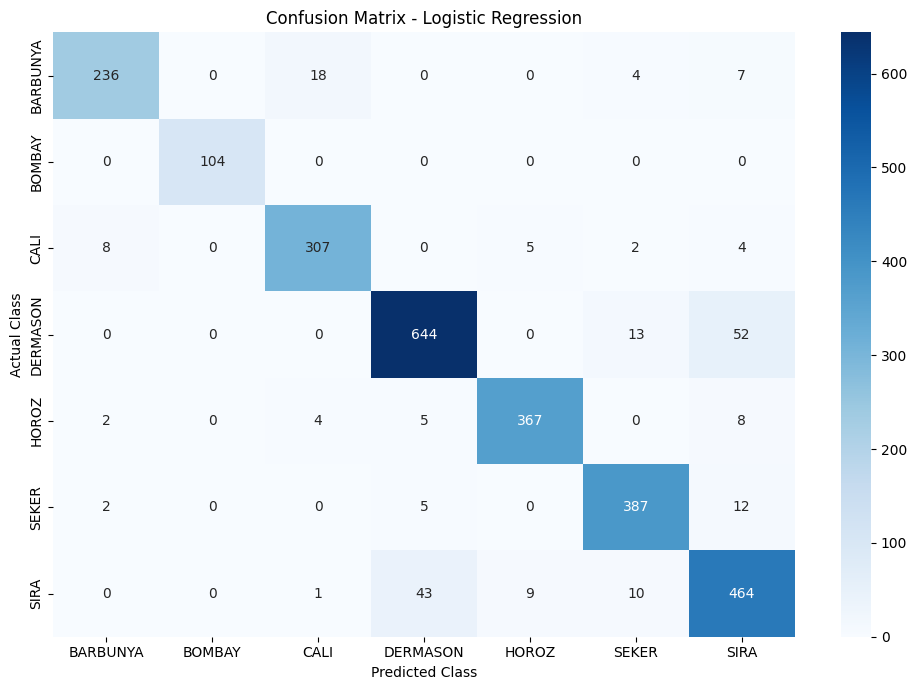

In [26]:

# Step 17: Confusion Matrix for Logistic Regression

logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [27]:

# Step 18: Classification Report

print("Classification Report - Logistic Regression")

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Classification Report - Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.95      0.94       406
        SIRA       0.85      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [28]:

# Step 19: Creating and training the Decision Tree model

# Create the Decision Tree classifier
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model using training data
decision_tree_model.fit(X_train_scaled, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [29]:

# Step 20: Predicting bean categories

decision_tree_predictions = decision_tree_model.predict(
    X_test_scaled
)

print("First 10 Actual Values:")
print(label_encoder.inverse_transform(y_test[:10]))

print("\nFirst 10 Predicted Values:")
print(
    label_encoder.inverse_transform(
        decision_tree_predictions[:10]
    )
)


First 10 Actual Values:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'BARBUNYA' 'HOROZ']

First 10 Predicted Values:
['DERMASON' 'BOMBAY' 'SIRA' 'SEKER' 'BARBUNYA' 'SEKER' 'DERMASON' 'SIRA'
 'CALI' 'HOROZ']


In [30]:

# Step 21: Evaluating Decision Tree

# Accuracy
decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_predictions
)

# Probability predictions for AUC
decision_tree_probabilities = decision_tree_model.predict_proba(
    X_test_scaled
)

# AUC Score
decision_tree_auc = roc_auc_score(
    y_test,
    decision_tree_probabilities,
    multi_class='ovr',
    average='macro'
)

# Precision
decision_tree_precision = precision_score(
    y_test,
    decision_tree_predictions,
    average='macro',
    zero_division=0
)

# Recall
decision_tree_recall = recall_score(
    y_test,
    decision_tree_predictions,
    average='macro',
    zero_division=0
)

# F1 Score
decision_tree_f1 = f1_score(
    y_test,
    decision_tree_predictions,
    average='macro',
    zero_division=0
)

# Matthews Correlation Coefficient
decision_tree_mcc = matthews_corrcoef(
    y_test,
    decision_tree_predictions
)

# Display results
print("DECISION TREE - PERFORMANCE")
print("----------------------------------")

print("Accuracy:", round(decision_tree_accuracy, 4))
print("AUC Score:", round(decision_tree_auc, 4))
print("Precision:", round(decision_tree_precision, 4))
print("Recall:", round(decision_tree_recall, 4))
print("F1 Score:", round(decision_tree_f1, 4))
print("MCC Score:", round(decision_tree_mcc, 4))


DECISION TREE - PERFORMANCE
----------------------------------
Accuracy: 0.892
AUC Score: 0.945
Precision: 0.9075
Recall: 0.909
F1 Score: 0.9081
MCC Score: 0.8696


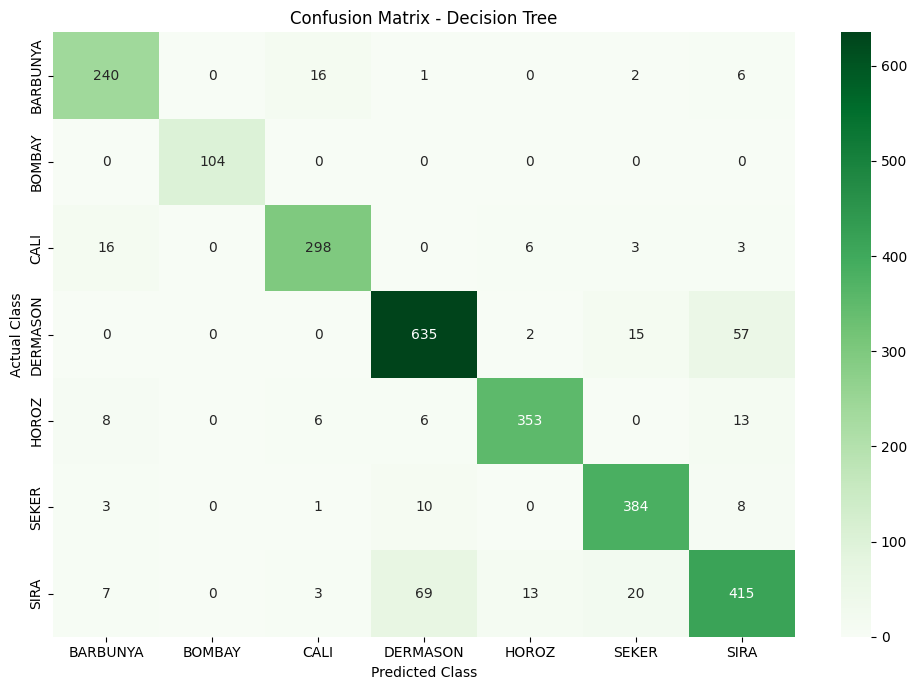

In [31]:

# Step 22: Confusion Matrix for Decision Tree

decision_tree_cm = confusion_matrix(
    y_test,
    decision_tree_predictions
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    decision_tree_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [32]:

# Step 23: Classification Report for Decision Tree

print("Classification Report - Decision Tree")

print(
    classification_report(
        y_test,
        decision_tree_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)


Classification Report - Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.91      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.91      0.92       326
    DERMASON       0.88      0.90      0.89       709
       HOROZ       0.94      0.91      0.93       386
       SEKER       0.91      0.95      0.93       406
        SIRA       0.83      0.79      0.81       527

    accuracy                           0.89      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.89      0.89      0.89      2723



In [33]:

# Step 24: Storing the first two model results

model_results = {
    "Logistic Regression": {
        "Accuracy": logistic_accuracy,
        "AUC": logistic_auc,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1 Score": logistic_f1,
        "MCC": logistic_mcc
    },

    "Decision Tree": {
        "Accuracy": decision_tree_accuracy,
        "AUC": decision_tree_auc,
        "Precision": decision_tree_precision,
        "Recall": decision_tree_recall,
        "F1 Score": decision_tree_f1,
        "MCC": decision_tree_mcc
    }
}

# Display the comparison so far
comparison_table = pd.DataFrame(model_results).T

display(comparison_table.round(4))


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696


In [34]:
# STEP 8: K-NEAREST NEIGHBORS (KNN)

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test_scaled)

# Get prediction probabilities
knn_probabilities = knn_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, knn_predictions)

knn_auc = roc_auc_score(
    y_test,
    knn_probabilities,
    multi_class='ovr',
    average='macro'
)

knn_precision = precision_score(
    y_test, knn_predictions, average='macro', zero_division=0
)

knn_recall = recall_score(
    y_test, knn_predictions, average='macro', zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_predictions, average='macro', zero_division=0
)

knn_mcc = matthews_corrcoef(y_test, knn_predictions)

# Display results
print("KNN MODEL RESULTS")
print("-------------------------")
print("Accuracy:", round(knn_accuracy, 4))
print("AUC:", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1 Score:", round(knn_f1, 4))
print("MCC:", round(knn_mcc, 4))

KNN MODEL RESULTS
-------------------------
Accuracy: 0.9166
AUC: 0.9833
Precision: 0.932
Recall: 0.9271
F1 Score: 0.9293
MCC: 0.8992


In [35]:
print("Classification Report - KNN")

print(
    classification_report(
        y_test,
        knn_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Classification Report - KNN
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.95      0.94      0.95       406
        SIRA       0.84      0.87      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [36]:
model_results["KNN"] = {
    "Accuracy": knn_accuracy,
    "AUC": knn_auc,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1 Score": knn_f1,
    "MCC": knn_mcc
}

comparison_table = pd.DataFrame(model_results).T

display(comparison_table.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992


In [37]:
# STEP 9: GAUSSIAN NAIVE BAYES

# Create the Gaussian Naive Bayes model
naive_bayes_model = GaussianNB()

# Train the model
naive_bayes_model.fit(X_train_scaled, y_train)

# Make predictions
naive_bayes_predictions = naive_bayes_model.predict(X_test_scaled)

# Get prediction probabilities
naive_bayes_probabilities = naive_bayes_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
naive_bayes_accuracy = accuracy_score(y_test, naive_bayes_predictions)

naive_bayes_auc = roc_auc_score(
    y_test,
    naive_bayes_probabilities,
    multi_class='ovr',
    average='macro'
)

naive_bayes_precision = precision_score(
    y_test, naive_bayes_predictions, average='macro', zero_division=0
)

naive_bayes_recall = recall_score(
    y_test, naive_bayes_predictions, average='macro', zero_division=0
)

naive_bayes_f1 = f1_score(
    y_test, naive_bayes_predictions, average='macro', zero_division=0
)

naive_bayes_mcc = matthews_corrcoef(
    y_test, naive_bayes_predictions
)

# Display results
print("GAUSSIAN NAIVE BAYES RESULTS")
print("----------------------------")
print("Accuracy:", round(naive_bayes_accuracy, 4))
print("AUC:", round(naive_bayes_auc, 4))
print("Precision:", round(naive_bayes_precision, 4))
print("Recall:", round(naive_bayes_recall, 4))
print("F1 Score:", round(naive_bayes_f1, 4))
print("MCC:", round(naive_bayes_mcc, 4))

GAUSSIAN NAIVE BAYES RESULTS
----------------------------
Accuracy: 0.8979
AUC: 0.9916
Precision: 0.9112
Recall: 0.9092
F1 Score: 0.9091
MCC: 0.8773


In [38]:
print("Classification Report - Gaussian Naive Bayes")

print(
    classification_report(
        y_test,
        naive_bayes_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Classification Report - Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.80      0.85       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.93      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       386
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.89      0.84       527

    accuracy                           0.90      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.90      0.90      0.90      2723



In [39]:
model_results["Gaussian Naive Bayes"] = {
    "Accuracy": naive_bayes_accuracy,
    "AUC": naive_bayes_auc,
    "Precision": naive_bayes_precision,
    "Recall": naive_bayes_recall,
    "F1 Score": naive_bayes_f1,
    "MCC": naive_bayes_mcc
}

comparison_table = pd.DataFrame(model_results).T

display(comparison_table.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773


In [40]:
# STEP 10: SUPPORT VECTOR MACHINE (SVM)

# Create the SVM model
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_scaled)

# Get prediction probabilities
svm_probabilities = svm_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, svm_predictions)

svm_auc = roc_auc_score(
    y_test,
    svm_probabilities,
    multi_class='ovr',
    average='macro'
)

svm_precision = precision_score(
    y_test, svm_predictions, average='macro', zero_division=0
)

svm_recall = recall_score(
    y_test, svm_predictions, average='macro', zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_predictions, average='macro', zero_division=0
)

svm_mcc = matthews_corrcoef(y_test, svm_predictions)

# Display results
print("SUPPORT VECTOR MACHINE RESULTS")
print("------------------------------")
print("Accuracy:", round(svm_accuracy, 4))
print("AUC:", round(svm_auc, 4))
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1 Score:", round(svm_f1, 4))
print("MCC:", round(svm_mcc, 4))

SUPPORT VECTOR MACHINE RESULTS
------------------------------
Accuracy: 0.9221
AUC: 0.9949
Precision: 0.9359
Recall: 0.933
F1 Score: 0.9343
MCC: 0.9059


In [41]:
print("Classification Report - SVM")

print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Classification Report - SVM
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [42]:
model_results["SVM"] = {
    "Accuracy": svm_accuracy,
    "AUC": svm_auc,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1 Score": svm_f1,
    "MCC": svm_mcc
}

comparison_table = pd.DataFrame(model_results).T

print("FINAL MODEL COMPARISON")
display(comparison_table.round(4))

FINAL MODEL COMPARISON


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773
SVM,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


In [43]:
# STEP 11: SAVE ALL FIVE TRAINED MODELS

# Create a folder to store the models
os.makedirs("models", exist_ok=True)

# Store all five trained models
trained_models = {
    "logistic_regression": logistic_model,
    "decision_tree": decision_tree_model,
    "knn": knn_model,
    "gaussian_naive_bayes": naive_bayes_model,
    "svm": svm_model
}

# Save each model with its preprocessing information
for model_name, model in trained_models.items():

    model_artifact = {
        "model": model,
        "scaler": scaler,
        "label_encoder": label_encoder,
        "feature_names": list(X.columns)
    }

    file_path = f"models/{model_name}.joblib"

    joblib.dump(model_artifact, file_path)

    print(f"{model_name} saved successfully!")

print("\nAll five models have been saved!")

logistic_regression saved successfully!
decision_tree saved successfully!
knn saved successfully!
gaussian_naive_bayes saved successfully!
svm saved successfully!

All five models have been saved!


In [44]:
# Display saved model files

print("SAVED MODEL FILES")
print("-----------------")

for filename in os.listdir("models"):
    print(filename)

SAVED MODEL FILES
-----------------
gaussian_naive_bayes.joblib
knn.joblib
svm.joblib
decision_tree.joblib
logistic_regression.joblib


In [45]:
# STEP 12: CREATE TEST DATA CSV

# Copy the original test features
test_data = X_test.copy()

# Convert encoded target values back to original bean names
test_data["Class"] = label_encoder.inverse_transform(y_test)

# Save as CSV
test_data.to_csv("test_data.csv", index=False)

print("Test data CSV created successfully!")

print("Test dataset shape:", test_data.shape)

display(test_data.head())

Test data CSV created successfully!
Test dataset shape: (2723, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA


In [46]:
# STEP 13: SAVE FINAL MODEL COMPARISON

comparison_table = pd.DataFrame(model_results).T

comparison_table.to_csv("model_comparison.csv")

display(comparison_table.round(4))

print("Model comparison saved successfully!")

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9166,0.9833,0.9320,0.9271,0.9293,0.8992
Gaussian Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773
SVM,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


Model comparison saved successfully!


In [47]:
# STEP 14: CHECK PROJECT FILES

print("PROJECT FILE VERIFICATION")
print("-------------------------")

print("\nSaved models:")

for filename in sorted(os.listdir("models")):
    print("✔", filename)

print("\nTest data CSV:")
print("✔ test_data.csv")

print("\nModel comparison:")
print("✔ model_comparison.csv")

PROJECT FILE VERIFICATION
-------------------------

Saved models:
✔ decision_tree.joblib
✔ gaussian_naive_bayes.joblib
✔ knn.joblib
✔ logistic_regression.joblib
✔ svm.joblib

Test data CSV:
✔ test_data.csv

Model comparison:
✔ model_comparison.csv


In [48]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Dry Bean Classification",
    page_icon="🌱",
    layout="wide"
)

st.title("🌱 Dry Bean Classification System")

st.write(
    "A machine learning application to classify dry bean varieties "
    "using five trained classification models."
)

st.divider()

# --------------------------------------------------
# 2. MODEL FILE LOCATIONS
# --------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent
MODEL_DIR = BASE_DIR / "models"

MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_naive_bayes.joblib",
    "SVM": "svm.joblib"
}

# --------------------------------------------------
# 3. LOAD SAVED MODELS
# --------------------------------------------------

@st.cache_resource
def load_models():

    loaded_models = {}

    for model_name, filename in MODEL_FILES.items():

        file_path = MODEL_DIR / filename

        artifact = joblib.load(file_path)

        loaded_models[model_name] = artifact

    return loaded_models


try:
    models = load_models()
    st.success("All five trained models loaded successfully!")

except Exception as error:
    st.error(f"Unable to load model files: {error}")
    st.stop()

# --------------------------------------------------
# 4. UPLOAD TEST DATA
# --------------------------------------------------

st.header("1. Upload Test Dataset")

uploaded_file = st.file_uploader(
    "Upload a CSV file containing the 16 input features and Class column",
    type=["csv"]
)

if uploaded_file is not None:

    try:
        test_data = pd.read_csv(uploaded_file)

        st.success("Dataset uploaded successfully!")

        st.subheader("Dataset Preview")
        st.dataframe(test_data.head())

        st.write("Dataset shape:", test_data.shape)

        # --------------------------------------------------
        # 5. VALIDATE DATASET
        # --------------------------------------------------

        first_artifact = models["Logistic Regression"]

        feature_names = first_artifact["feature_names"]

        required_columns = feature_names + ["Class"]

        missing_columns = [
            column for column in required_columns
            if column not in test_data.columns
        ]

        if missing_columns:

            st.error(
                f"Missing required columns: {missing_columns}"
            )
            st.stop()

        # Select only the required input features
        X = test_data[feature_names].copy()

        # Convert input features to numeric values
        X = X.apply(pd.to_numeric, errors="coerce")

        if X.isnull().values.any():

            st.error(
                "The uploaded dataset contains missing or "
                "non-numeric feature values."
            )
            st.stop()

        # Get actual target values
        actual_classes = test_data["Class"].astype(str)

        label_encoder = first_artifact["label_encoder"]

        try:
            y_true = label_encoder.transform(actual_classes)

        except ValueError:

            st.error(
                "The Class column contains unknown bean categories. "
                "Please check the target labels."
            )
            st.stop()

        # --------------------------------------------------
        # 6. MODEL SELECTION
        # --------------------------------------------------

        st.divider()

        st.header("2. Select Classification Model")

        selected_model_name = st.selectbox(
            "Choose a machine learning model",
            list(MODEL_FILES.keys())
        )

        # --------------------------------------------------
        # 7. EVALUATE ALL FIVE MODELS
        # --------------------------------------------------

        st.header("3. Model Performance Comparison")

        all_results = {}
        all_predictions = {}

        for model_name, artifact in models.items():

            model = artifact["model"]
            scaler = artifact["scaler"]
            encoder = artifact["label_encoder"]

            # Apply the saved scaler
            X_scaled = scaler.transform(X)

            # Predict target classes
            predictions = model.predict(X_scaled)

            # Predict class probabilities
            probabilities = model.predict_proba(X_scaled)

            # Calculate six evaluation metrics
            accuracy = accuracy_score(y_true, predictions)

            auc = roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="macro"
            )

            precision = precision_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0
            )

            recall = recall_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0
            )

            f1 = f1_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0
            )

            mcc = matthews_corrcoef(
                y_true,
                predictions
            )

            all_results[model_name] = {
                "Accuracy": accuracy,
                "AUC": auc,
                "Precision": precision,
                "Recall": recall,
                "F1 Score": f1,
                "MCC": mcc
            }

            all_predictions[model_name] = predictions

        # Display comparison table
        results_df = pd.DataFrame(all_results).T

        st.dataframe(
            results_df.style.format("{:.4f}"),
            use_container_width=True
        )

        # --------------------------------------------------
        # 8. SELECTED MODEL RESULTS
        # --------------------------------------------------

        st.divider()

        st.header("4. Selected Model Evaluation")

        selected_predictions = all_predictions[
            selected_model_name
        ]

        selected_metrics = all_results[
            selected_model_name
        ]

        st.subheader(selected_model_name)

        # Display metrics
        col1, col2, col3 = st.columns(3)

        col1.metric(
            "Accuracy",
            f"{selected_metrics['Accuracy']:.4f}"
        )

        col2.metric(
            "AUC",
            f"{selected_metrics['AUC']:.4f}"
        )

        col3.metric(
            "Precision",
            f"{selected_metrics['Precision']:.4f}"
        )

        col4, col5, col6 = st.columns(3)

        col4.metric(
            "Recall",
            f"{selected_metrics['Recall']:.4f}"
        )

        col5.metric(
            "F1 Score",
            f"{selected_metrics['F1 Score']:.4f}"
        )

        col6.metric(
            "MCC",
            f"{selected_metrics['MCC']:.4f}"
        )

        # --------------------------------------------------
        # 9. CONFUSION MATRIX
        # --------------------------------------------------

        st.subheader("Confusion Matrix")

        class_names = label_encoder.classes_

        cm = confusion_matrix(
            y_true,
            selected_predictions,
            labels=np.arange(len(class_names))
        )

        fig, ax = plt.subplots(figsize=(10, 7))

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names,
            ax=ax
        )

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("Actual Class")
        ax.set_title(
            f"Confusion Matrix - {selected_model_name}"
        )

        plt.xticks(rotation=45)
        plt.yticks(rotation=0)
        plt.tight_layout()

        st.pyplot(fig)

        plt.close(fig)

        # --------------------------------------------------
        # 10. CLASSIFICATION REPORT
        # --------------------------------------------------

        st.subheader("Classification Report")

        report = classification_report(
            y_true,
            selected_predictions,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )

        report_df = pd.DataFrame(report).transpose()

        st.dataframe(
            report_df.round(4),
            use_container_width=True
        )

        st.success("Model evaluation completed successfully!")

    except Exception as error:

        st.error(f"An error occurred during evaluation: {error}")

else:

    st.info(
        "Please upload a test CSV file to begin model evaluation."
    )

st.divider()

st.caption(
    "Dry Bean Classification Project | Machine Learning Assignment"
)

Writing app.py


In [49]:
%%writefile requirements.txt

streamlit
scikit-learn
numpy
pandas
matplotlib
seaborn
joblib

Writing requirements.txt


In [50]:
import py_compile
import os

try:
    py_compile.compile("app.py", doraise=True)
    print("SUCCESS: app.py has no syntax errors!")

except Exception as error:
    print("ERROR:", error)

print("\nProject files:")
print(os.listdir("."))

SUCCESS: app.py has no syntax errors!

Project files:
['.config', 'dry+bean+dataset.zip', '__pycache__', 'model_comparison.csv', 'requirements.txt', 'DryBeanData', 'models', 'test_data.csv', 'app.py', 'sample_data']


In [51]:
import os
import shutil

# Create a folder for the project
project_folder = "Dry_Bean_Classification"

os.makedirs(project_folder, exist_ok=True)

# Copy the required files
files_to_copy = [
    "app.py",
    "requirements.txt",
    "test_data.csv",
    "model_comparison.csv"
]

for filename in files_to_copy:
    shutil.copy(filename, project_folder)

# Copy all five saved models
shutil.copytree(
    "models",
    os.path.join(project_folder, "models"),
    dirs_exist_ok=True
)

print("Project folder created successfully!")

print("\nFiles inside the project:")

for root, folders, files in os.walk(project_folder):
    for filename in files:
        print(os.path.join(root, filename))

Project folder created successfully!

Files inside the project:
Dry_Bean_Classification/model_comparison.csv
Dry_Bean_Classification/requirements.txt
Dry_Bean_Classification/test_data.csv
Dry_Bean_Classification/app.py
Dry_Bean_Classification/models/gaussian_naive_bayes.joblib
Dry_Bean_Classification/models/knn.joblib
Dry_Bean_Classification/models/svm.joblib
Dry_Bean_Classification/models/decision_tree.joblib
Dry_Bean_Classification/models/logistic_regression.joblib


In [52]:
from google.colab import files
import shutil

# Create ZIP file
shutil.make_archive(
    "Dry_Bean_Classification",
    "zip",
    "Dry_Bean_Classification"
)

# Download to your computer
files.download("Dry_Bean_Classification.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>